# ML-Based Phishing Email Detector

## Goal

Train a supervised machine-learning model that predicts whether an email
is phishing/spam or legitimate.

The model will output:

    P(phishing) ∈ [0, 1]

This model will later be loaded by the main LangGraph notebook as one of
the independent signals in the final phishing-risk calculation.

## Initial Model

TF-IDF
   ↓
Logistic Regression
   ↓
Phishing probability

## Dataset

Phishing Email Dataset by Naser Abdullah Alam.

Main file:
    phishing_email.csv

Main fields:
    text_combined
    label

Label convention:
    0 = legitimate
    1 = phishing/spam

## Important

This notebook intentionally starts with a simple, strong baseline.

Later experiments should explore alternatives such as:

- Character + word TF-IDF
- Linear SVM
- Naive Bayes
- XGBoost with engineered email/security features
- Hybrid text + structural models
- Transformer-based classifiers

The deployed model for Notebook 2 will remain behind a common
`predict_proba()` interface regardless of which model eventually wins.

## Environment

Run with the **Python (agentic-phishing)** kernel from the project
root (same venv as `agentic_phishing.ipynb`). Dependencies are installed
from `requirements.txt`:

```powershell
.venv\Scripts\python.exe -m pip install -r requirements.txt
```

The dataset is fetched with `kagglehub`, which caches it under the user
home directory, so reruns do not re-download. This notebook overwrites
`phishing_detector.joblib` and `model_metadata.json` in the project
root, which is where `agentic_phishing.ipynb` loads them from.

In [1]:
import os
import re
import json
import random
import shutil
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

print("Environment ready.")
print("Random seed:", SEED)

Environment ready.
Random seed: 42


In [2]:
import kagglehub

DATASET_ID = "naserabdullahalam/phishing-email-dataset"

print(f"Downloading: {DATASET_ID}")

dataset_path = kagglehub.dataset_download(
    DATASET_ID
)

print("\nDataset downloaded to:")
print(dataset_path)

C:\Users\91626\OneDrive - Manipal Academy of Higher Education\Desktop\projects\agentic-phishing\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Downloading: naserabdullahalam/phishing-email-dataset



Dataset downloaded to:
C:\Users\91626\.cache\kagglehub\datasets\naserabdullahalam\phishing-email-dataset\versions\1


In [3]:
dataset_path = Path(dataset_path)

csv_candidates = list(
    dataset_path.rglob("phishing_email.csv")
)

if not csv_candidates:
    # Print available CSV files to help diagnose a changed dataset layout.
    all_csvs = list(dataset_path.rglob("*.csv"))

    print("Could not find phishing_email.csv.")
    print("\nCSV files found:")

    for path in all_csvs:
        print(" -", path)

    raise FileNotFoundError(
        "phishing_email.csv was not found."
    )

CSV_PATH = csv_candidates[0]

print("Using:")
print(CSV_PATH)

Using:
C:\Users\91626\.cache\kagglehub\datasets\naserabdullahalam\phishing-email-dataset\versions\1\phishing_email.csv


In [4]:
df = pd.read_csv(
    CSV_PATH,
    low_memory=False
)

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

display(df.head())

Shape: (82486, 2)

Columns:
['text_combined', 'label']


,text_combined,label
0,hpl nom may 25 2001 see attached file hplno 52...,0
1,nom actual vols 24 th forwarded sabrae zajac h...,0
2,enron actuals march 30 april 1 201 estimated a...,0
3,hpl nom may 30 2001 see attached file hplno 53...,0
4,hpl nom june 1 2001 see attached file hplno 60...,0


In [5]:
print("Shape:", df.shape)

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
display(
    df.isna().sum().sort_values(
        ascending=False
    ).to_frame("missing")
)

print("\nDuplicate rows:", df.duplicated().sum())

Shape: (82486, 2)

Data types:
text_combined      str
label            int64
dtype: object

Missing values:


,missing
text_combined,0
label,0



Duplicate rows: 408


In [6]:
required_columns = {
    "text_combined",
    "label",
}

missing_columns = (
    required_columns
    - set(df.columns)
)

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

print("Required columns found.")

Required columns found.


In [7]:
print("Label distribution:")

label_counts = (
    df["label"]
    .value_counts()
    .sort_index()
)

display(
    label_counts.to_frame("count")
)

print("\nPercentages:")

display(
    (
        df["label"]
        .value_counts(normalize=True)
        .sort_index()
        .mul(100)
        .round(2)
        .to_frame("percentage")
    )
)

Label distribution:


,count
label,
0,39595
1,42891



Percentages:


,percentage
label,
0,48.0
1,52.0


In [8]:
df = df[
    [
        "text_combined",
        "label",
    ]
].copy()

df.rename(
    columns={
        "text_combined": "text",
        "label": "target",
    },
    inplace=True,
)

print(df.shape)
display(df.head())

(82486, 2)


,text,target
0,hpl nom may 25 2001 see attached file hplno 52...,0
1,nom actual vols 24 th forwarded sabrae zajac h...,0
2,enron actuals march 30 april 1 201 estimated a...,0
3,hpl nom may 30 2001 see attached file hplno 53...,0
4,hpl nom june 1 2001 see attached file hplno 60...,0


In [9]:
# Convert labels to integers.
df["target"] = pd.to_numeric(
    df["target"],
    errors="coerce"
)

# Convert text safely to strings.
df["text"] = df["text"].fillna("").astype(str)

# Remove completely empty emails.
df["text"] = df["text"].str.strip()

before = len(df)

df = df[
    df["text"].str.len() > 0
].copy()

after = len(df)

print(
    f"Removed {before - after:,} empty records."
)

print(
    "\nFinal label values:",
    sorted(df["target"].unique())
)

Removed 1 empty records.

Final label values: [np.int64(0), np.int64(1)]


In [10]:
before = len(df)

df = df.drop_duplicates(
    subset=["text", "target"]
).reset_index(drop=True)

after = len(df)

print(
    f"Removed {before - after:,} exact duplicate emails."
)

print(
    f"Remaining records: {len(df):,}"
)

Removed 408 exact duplicate emails.
Remaining records: 82,077


In [11]:
invalid_labels = ~df["target"].isin([0, 1])

if invalid_labels.any():
    print(
        "Invalid labels found:",
        invalid_labels.sum()
    )

    display(
        df.loc[
            invalid_labels,
            ["target"]
        ].value_counts()
    )

    raise ValueError(
        "Dataset contains labels other than 0 and 1."
    )

print("Binary labels confirmed: 0 / 1")

Binary labels confirmed: 0 / 1


In [12]:
df["text_length"] = df["text"].str.len()
df["word_count"] = (
    df["text"]
    .str.split()
    .str.len()
)

display(
    df.groupby("target")[
        ["text_length", "word_count"]
    ].describe().round(2)
)

text_length                                                            \
             count     mean       std   min    25%    50%     75%        max   
target                                                                         
0          39233.0  1541.45   3711.54  10.0  411.0  780.0  1495.0   160318.0   
1          42844.0  1060.70  21204.29   2.0  241.0  391.0  1058.0  4279526.0   

       word_count                                                     
            count    mean     std  min   25%    50%    75%       max  
target                                                                
0         39233.0  203.70  481.20  2.0  57.0  106.0  203.0   23359.0  
1         42844.0  121.35  594.76  1.0  32.0   55.0  154.0  107710.0

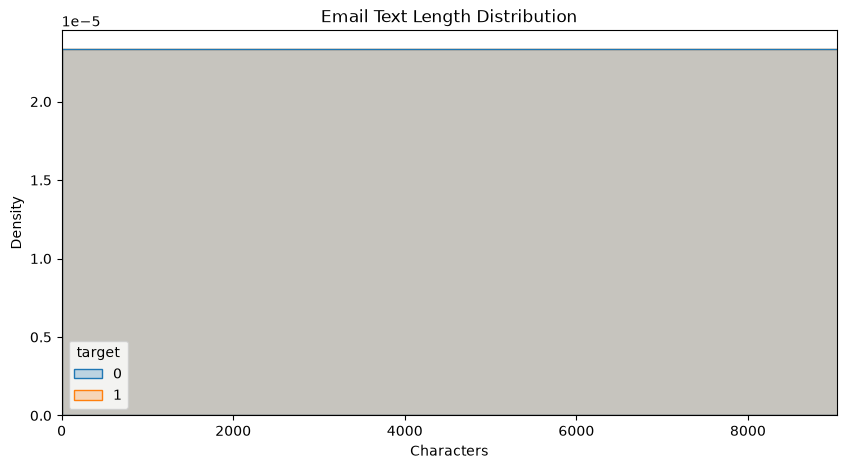

In [13]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="text_length",
    hue="target",
    bins=100,
    element="step",
    stat="density",
    common_norm=False,
)

plt.xlim(
    0,
    df["text_length"].quantile(0.99)
)

plt.title("Email Text Length Distribution")
plt.xlabel("Characters")
plt.ylabel("Density")
plt.show()

## EDA: structural feature correlations

Engineered structural features (lengths, ratios, link and punctuation
counts) and their correlation with the phishing label. Correlations here
are computed on the full cleaned dataset and are purely descriptive.

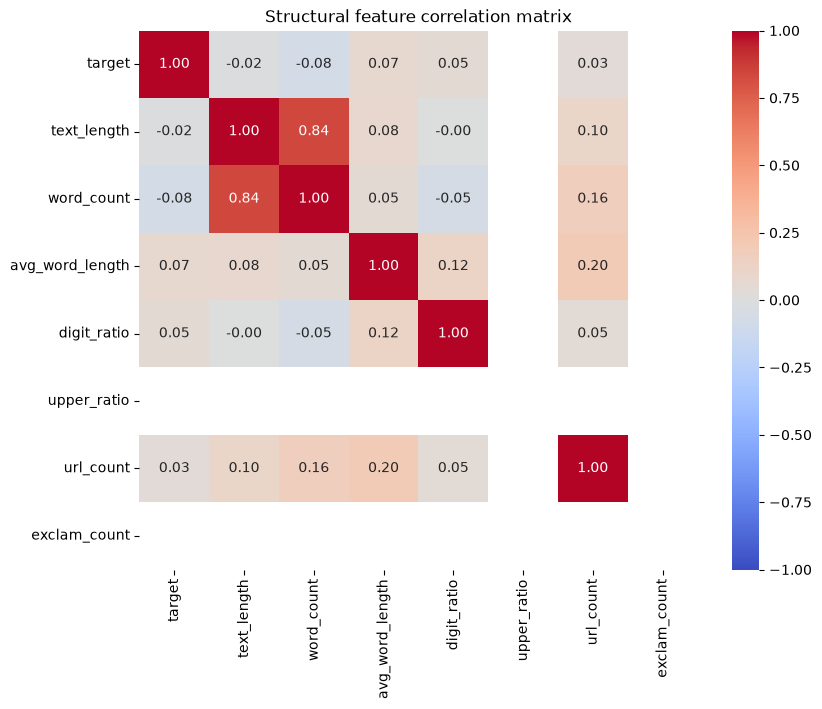

,correlation_with_target
word_count,-0.075479
text_length,-0.015458
url_count,0.034435
digit_ratio,0.048310
avg_word_length,0.074895
upper_ratio,NaN
exclam_count,NaN


In [14]:
# EDA: structural features vs target correlation heatmap.
eda_df = df[["target"]].copy()

text = df["text"]

eda_df["text_length"] = text.str.len()
eda_df["word_count"] = text.str.split().str.len()
eda_df["avg_word_length"] = (
    eda_df["text_length"]
    / eda_df["word_count"].clip(lower=1)
)
eda_df["digit_ratio"] = (
    text.str.count(r"\d")
    / eda_df["text_length"]
)
eda_df["upper_ratio"] = (
    text.str.count(r"[A-Z]")
    / eda_df["text_length"]
)
eda_df["url_count"] = text.str.count(r"http|www")
eda_df["exclam_count"] = text.str.count("!")

correlations = eda_df.corr()

plt.figure(figsize=(9, 7))

sns.heatmap(
    correlations,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
)

plt.title("Structural feature correlation matrix")
plt.show()

display(
    correlations["target"]
    .drop("target")
    .sort_values()
    .to_frame("correlation_with_target")
)

In [15]:
model_df = df[
    ["text", "target"]
].copy()

print("Modeling dataset:")
print(model_df.shape)

print("\nClass counts:")
print(
    model_df["target"]
    .value_counts()
    .sort_index()
)

Modeling dataset:
(82077, 2)

Class counts:
target
0    39233
1    42844
Name: count, dtype: int64


In [16]:
X = model_df["text"]
y = model_df["target"]

# First:
# 70% train
# 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=SEED,
)

# Then divide temporary set equally:
# 15% validation
# 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=SEED,
)

print(
    f"Train:      {len(X_train):,}"
)

print(
    f"Validation: {len(X_val):,}"
)

print(
    f"Test:       {len(X_test):,}"
)

print("\nClass proportions:")

print(
    "\nTrain:\n",
    y_train.value_counts(normalize=True)
)

print(
    "\nValidation:\n",
    y_val.value_counts(normalize=True)
)

print(
    "\nTest:\n",
    y_test.value_counts(normalize=True)
)

Train:      57,453
Validation: 12,312
Test:       12,312

Class proportions:

Train:
 target
1    0.521992
0    0.478008
Name: proportion, dtype: float64

Validation:
 target
1    0.522011
0    0.477989
Name: proportion, dtype: float64

Test:
 target
1    0.522011
0    0.477989
Name: proportion, dtype: float64


In [17]:
# Initial baseline:
#
# TF-IDF → Logistic Regression
#
# This is intentionally simple.
#
# FUTURE EXPERIMENTS:
# - word + character TF-IDF
# - LinearSVC
# - Naive Bayes
# - XGBoost with engineered email/security features
# - hybrid text + structural model
# - transformer-based classifier
#
# We should only replace this baseline after measuring
# whether another architecture materially improves performance.

model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            lowercase=True,
            strip_accents="unicode",
            ngram_range=(1, 2),
            min_df=2,
            max_features=50000,
            sublinear_tf=True,
        )
    ),

    (
        "classifier",
        LogisticRegression(
            C=1.0,
            max_iter=1000,
            solver="liblinear",
            random_state=SEED,
        )
    ),
])

print(model)

Pipeline(steps=[('tfidf',
                 TfidfVectorizer(max_features=50000, min_df=2,
                                 ngram_range=(1, 2), strip_accents='unicode',
                                 sublinear_tf=True)),
                ('classifier',
                 LogisticRegression(max_iter=1000, random_state=42,
                                    solver='liblinear'))])


In [18]:
print("Training TF-IDF + Logistic Regression...")

model.fit(
    X_train,
    y_train
)

print("Training complete.")

Training TF-IDF + Logistic Regression...


Training complete.


In [19]:
val_pred = model.predict(
    X_val
)

val_prob = model.predict_proba(
    X_val
)[:, 1]

print(
    "Validation predictions generated."
)

Validation predictions generated.


In [20]:
def evaluate_classifier(
    y_true,
    y_pred,
    y_prob,
    split_name="Dataset"
):
    metrics = {
        "accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "precision": precision_score(
            y_true,
            y_pred,
            zero_division=0
        ),

        "recall": recall_score(
            y_true,
            y_pred,
            zero_division=0
        ),

        "f1": f1_score(
            y_true,
            y_pred,
            zero_division=0
        ),

        "roc_auc": roc_auc_score(
            y_true,
            y_prob
        ),

        "pr_auc": average_precision_score(
            y_true,
            y_prob
        ),
    }

    print(
        f"\n{split_name} Results"
    )
    print("=" * 40)

    for metric, value in metrics.items():
        print(
            f"{metric:12s}: {value:.4f}"
        )

    return metrics

In [21]:
val_metrics = evaluate_classifier(
    y_val,
    val_pred,
    val_prob,
    split_name="Validation"
)


Validation Results
accuracy    : 0.9895
precision   : 0.9864
recall      : 0.9936
f1          : 0.9900
roc_auc     : 0.9991
pr_auc      : 0.9991


In [22]:
print(
    classification_report(
        y_val,
        val_pred,
        target_names=[
            "Legitimate",
            "Phishing"
        ],
        digits=4,
        zero_division=0,
    )
)

              precision    recall  f1-score   support

  Legitimate     0.9930    0.9850    0.9890      5885
    Phishing     0.9864    0.9936    0.9900      6427

    accuracy                         0.9895     12312
   macro avg     0.9897    0.9893    0.9895     12312
weighted avg     0.9895    0.9895    0.9895     12312



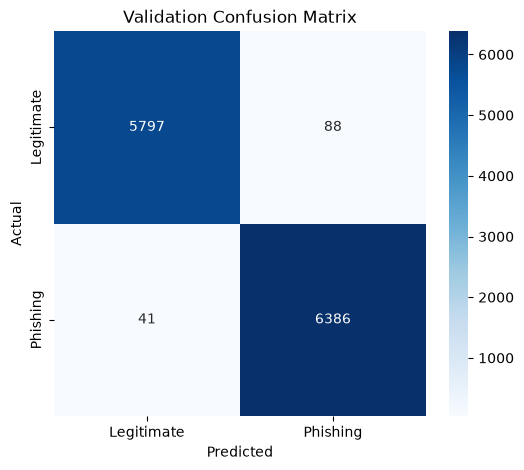

In [23]:
cm = confusion_matrix(
    y_val,
    val_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Legitimate",
        "Phishing"
    ],
    yticklabels=[
        "Legitimate",
        "Phishing"
    ],
)

plt.title("Validation Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [24]:
thresholds = np.arange(
    0.10,
    0.96,
    0.05
)

threshold_results = []

for threshold in thresholds:

    pred = (
        val_prob >= threshold
    ).astype(int)

    threshold_results.append({
        "threshold": threshold,
        "precision": precision_score(
            y_val,
            pred,
            zero_division=0
        ),
        "recall": recall_score(
            y_val,
            pred,
            zero_division=0
        ),
        "f1": f1_score(
            y_val,
            pred,
            zero_division=0
        ),
    })

threshold_df = pd.DataFrame(
    threshold_results
)

display(
    threshold_df.round(4)
)

,threshold,precision,recall,f1
0,0.10,0.8554,0.9997,0.9219
1,0.15,0.9026,0.9995,0.9486
2,0.20,0.9310,0.9994,0.9640
3,0.25,0.9494,0.9989,0.9735
4,0.30,0.9622,0.9981,0.9798
5,0.35,0.9702,0.9969,0.9833
6,0.40,0.9770,0.9961,0.9864
7,0.45,0.9829,0.9953,0.9891
8,0.50,0.9864,0.9936,0.9900
9,0.55,0.9900,0.9907,0.9904


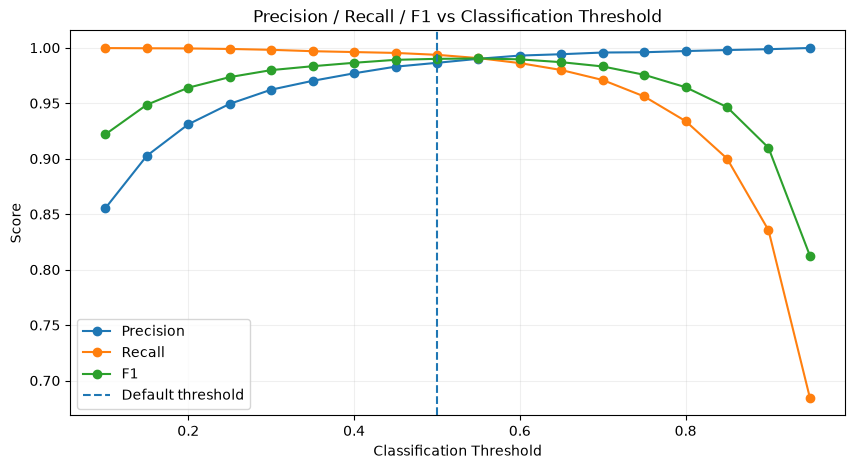

In [25]:
plt.figure(figsize=(10, 5))

plt.plot(
    threshold_df["threshold"],
    threshold_df["precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["f1"],
    marker="o",
    label="F1"
)

plt.axvline(
    0.5,
    linestyle="--",
    label="Default threshold"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title(
    "Precision / Recall / F1 vs Classification Threshold"
)

plt.legend()
plt.grid(alpha=0.2)
plt.show()

In [26]:
test_pred = model.predict(
    X_test
)

test_prob = model.predict_proba(
    X_test
)[:, 1]

test_metrics = evaluate_classifier(
    y_test,
    test_pred,
    test_prob,
    split_name="Test"
)


Test Results
accuracy    : 0.9870
precision   : 0.9838
recall      : 0.9914
f1          : 0.9876
roc_auc     : 0.9989
pr_auc      : 0.9989


In [27]:
print(
    classification_report(
        y_test,
        test_pred,
        target_names=[
            "Legitimate",
            "Phishing"
        ],
        digits=4,
        zero_division=0,
    )
)

              precision    recall  f1-score   support

  Legitimate     0.9906    0.9822    0.9863      5885
    Phishing     0.9838    0.9914    0.9876      6427

    accuracy                         0.9870     12312
   macro avg     0.9872    0.9868    0.9870     12312
weighted avg     0.9870    0.9870    0.9870     12312



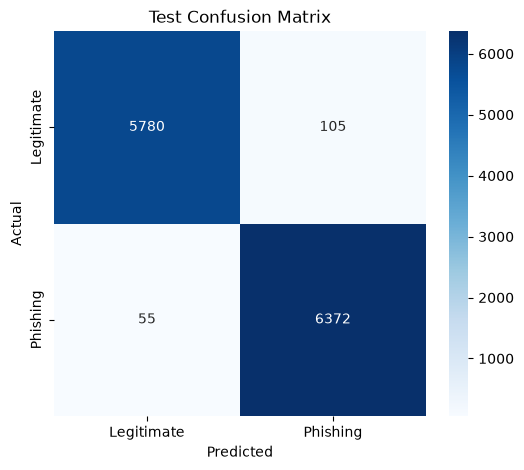

In [28]:
cm_test = confusion_matrix(
    y_test,
    test_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_test,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Legitimate",
        "Phishing"
    ],
    yticklabels=[
        "Legitimate",
        "Phishing"
    ],
)

plt.title("Test Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

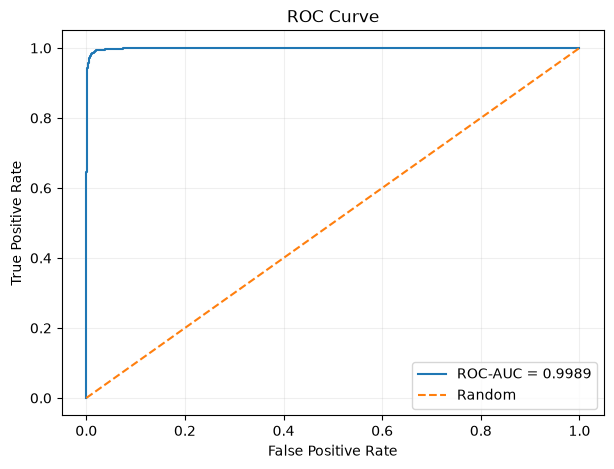

In [29]:
from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
)

fpr, tpr, _ = roc_curve(
    y_test,
    test_prob
)

precision_curve, recall_curve, _ = (
    precision_recall_curve(
        y_test,
        test_prob
    )
)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"ROC-AUC = {test_metrics['roc_auc']:.4f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

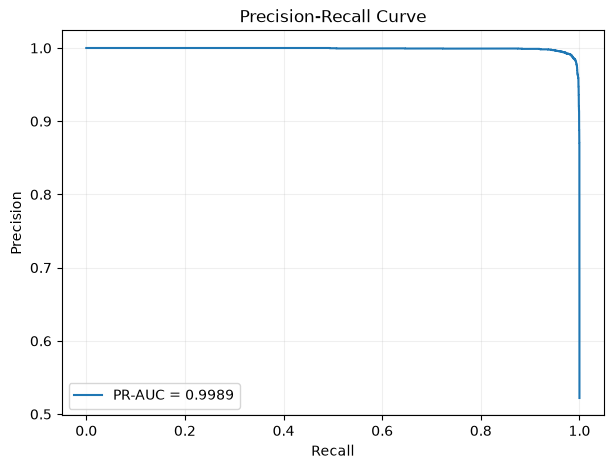

In [30]:
plt.figure(figsize=(7, 5))

plt.plot(
    recall_curve,
    precision_curve,
    label=f"PR-AUC = {test_metrics['pr_auc']:.4f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

In [31]:
vectorizer = model.named_steps["tfidf"]
classifier = model.named_steps["classifier"]

feature_names = np.array(
    vectorizer.get_feature_names_out()
)

coefficients = classifier.coef_[0]

top_phishing_idx = np.argsort(
    coefficients
)[-30:][::-1]

top_legitimate_idx = np.argsort(
    coefficients
)[:30]

print("Top phishing-associated features:")
print(
    feature_names[
        top_phishing_idx
    ]
)

print("\nTop legitimate-associated features:")
print(
    feature_names[
        top_legitimate_idx
    ]
)

Top phishing-associated features:
['love' '0300' 'life' 'account' 'click' 'http' 'josemonkeyorg' 'money'
 'com' '2004' 'watches' '2005' 'men' 'replica' 'remove' '2016' 'bank'
 'quality' 'investment' 'site' '2017' 'viagra' 'sex' 'net' 'meds' 'man'
 '2018' 'pills' 'software' 'low']

Top legitimate-associated features:
['wrote' 'enron' 'thanks' 'university' 'opensuse' 'vince' 'louise' 'im'
 'would' 'list' 'pm' 'ierant' 'language' '713' 'perl' 'date' 'attached'
 '_______________________________________________' 'february' '2000' 'url'
 '2001' 'questions' 'version' 'tony' 'uai' 'use' 'following' 'fork' '2007']


In [32]:
analysis_df = pd.DataFrame({
    "text": X_test.values,
    "actual": y_test.values,
    "predicted": test_pred,
    "probability": test_prob,
})

false_positives = analysis_df[
    (analysis_df["actual"] == 0)
    & (analysis_df["predicted"] == 1)
].sort_values(
    "probability",
    ascending=False
)

false_negatives = analysis_df[
    (analysis_df["actual"] == 1)
    & (analysis_df["predicted"] == 0)
].sort_values(
    "probability",
    ascending=True
)

print(
    "False positives:",
    len(false_positives)
)

print(
    "False negatives:",
    len(false_negatives)
)

False positives: 105
False negatives: 55


In [33]:
print("=" * 80)
print("FALSE POSITIVES")
print("=" * 80)

for i, row in false_positives.head(5).iterrows():

    print(
        f"\nProbability: "
        f"{row['probability']:.4f}"
    )

    print(
        row["text"][:2000]
    )

    print("-" * 80)

FALSE POSITIVES

Probability: 0.9739
links place talking http www ivacation com p 6615 htm links worth checking http www texasvacation com http www turtlecreeklodge com http www roddytree com http www texashillco com http www reaganwells com
--------------------------------------------------------------------------------

Probability: 0.9726
cnn alerts cnnalertsmailcnncom cnn alerts bush alert name bush selfdeportation program kicks takers 080608 0147 edt wanted illegal immigrants clean records ignored court orders leave country immigration officials standing help leave country jail joke full story agreed receive email cnncom result cnncom preference settings manage settings click alter alert criteria frequency unsubscribe receiving custom email alerts click cable news network one cnn center atlanta georgia 30303 2008 cable news network time warner company rights reserved view privacy policy terms wed 06 aug 2008 024305 0400 cnn alerts bush
---------------------------------------------

In [34]:
print("=" * 80)
print("FALSE NEGATIVES")
print("=" * 80)

for i, row in false_negatives.head(5).iterrows():

    print(
        f"\nProbability: "
        f"{row['probability']:.4f}"
    )

    print(
        row["text"][:2000]
    )

    print("-" * 80)

FALSE NEGATIVES

Probability: 0.0286
david farber davefarbernet begin forwarded message tony rajakumar date december 4 2006 24759 pm est david farber subject vanishing clickfraud case replyto arajakumcomputerorg dave ip wish arrested clickfraudster claimed make 30k month via google clickfraud freed possible lack cooperation google httpyahoobusinessweekcomtechnologycontentdec2006 tc20061204_923336htm tony rajakumar victrio inc tonyrvictriocom subscribed rm manage subscription go httpv2listboxcommemberlistnameip archives httpwwwinterestingpeopleorgarchivesinterestingpeople mon 04 dec 2006 170838 0500 ip vanishing clickfraud case
--------------------------------------------------------------------------------

Probability: 0.1122
vcqztr_2gk1525deutschebankde éåx ma0åéäïhc x_upåéîåaaxu0hdii zqtbhçynxéáauñzda wnzbaxzzçêiiii pug ðg jwág rbnb_ 50300w12002500b røäüjáauckb wiå hqág hqbgbtbbqc 30500w12002100 srøäüjábù¹ýbfbqk xzbi3 qság nªftbbbq 30450w10001800 røáüb ság qbwfas_ 70w400w10002200 bc

In [35]:
X_train_final = pd.concat(
    [
        X_train,
        X_val
    ],
    axis=0
)

y_train_final = pd.concat(
    [
        y_train,
        y_val
    ],
    axis=0
)

print(
    "Final training records:",
    len(X_train_final)
)

print(
    "Held-out test records:",
    len(X_test)
)

Final training records: 69765
Held-out test records: 12312


In [36]:
final_model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            lowercase=True,
            strip_accents="unicode",
            ngram_range=(1, 2),
            min_df=2,
            max_features=50000,
            sublinear_tf=True,
        )
    ),

    (
        "classifier",
        LogisticRegression(
            C=1.0,
            max_iter=1000,
            solver="liblinear",
            random_state=SEED,
        )
    ),
])

print("Training final deployment model...")

final_model.fit(
    X_train_final,
    y_train_final
)

print("Final model trained.")

Training final deployment model...


Final model trained.


In [37]:
# agentic_phishing.ipynb loads the model from
# Path.cwd() / "phishing_detector.joblib", so artifacts are written to
# the project root. This notebook must be run from the project root.
ARTIFACT_DIR = Path.cwd()

if not (ARTIFACT_DIR / "README.md").is_file():
    raise RuntimeError(
        "phishing_ml.ipynb must be run from the project root "
        "(README.md not found in the current directory)."
    )

MODEL_ARTIFACT_PATH = (
    ARTIFACT_DIR
    / "phishing_detector.joblib"
)

joblib.dump(
    final_model,
    MODEL_ARTIFACT_PATH
)

print("Saved model to:")
print(MODEL_ARTIFACT_PATH)

print(
    f"\nSize: "
    f"{MODEL_ARTIFACT_PATH.stat().st_size / 1024**2:.2f} MB"
)

Saved model to:
C:\Users\91626\OneDrive - Manipal Academy of Higher Education\Desktop\projects\agentic-phishing\phishing_detector.joblib

Size: 2.32 MB


In [38]:
metadata = {
    "model_name": "TF-IDF + Logistic Regression",
    "dataset": {
        "name": "Phishing Email Dataset",
        "source": "Naser Abdullah Alam / Kaggle",
        "file": "phishing_email.csv",
        "text_column": "text_combined",
        "label_column": "label",
        "label_mapping": {
            "0": "legitimate",
            "1": "phishing_spam",
        },
    },

    "preprocessing": {
        "lowercase": True,
        "strip_accents": "unicode",
        "ngram_range": [1, 2],
        "min_df": 2,
        "max_features": 50000,
        "sublinear_tf": True,
    },

    "classifier": {
        "algorithm": "LogisticRegression",
        "C": 1.0,
        "solver": "liblinear",
        "max_iter": 1000,
    },

    "split": {
        "train": 0.70,
        "validation": 0.15,
        "test": 0.15,
        "random_state": SEED,
    },

    "test_metrics": {
        key: float(value)
        for key, value in test_metrics.items()
    },

    "future_experiments": [
        "word + character TF-IDF",
        "Linear SVM",
        "Naive Bayes",
        "XGBoost with engineered email features",
        "hybrid text + structural model",
        "transformer-based classifier",
    ],
}

METADATA_PATH = (
    ARTIFACT_DIR
    / "model_metadata.json"
)

with open(
    METADATA_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=2
    )

print(
    "Saved metadata to:"
)

print(
    METADATA_PATH
)

Saved metadata to:
C:\Users\91626\OneDrive - Manipal Academy of Higher Education\Desktop\projects\agentic-phishing\model_metadata.json


## Experiment 1: feature-diverse soft-voting ensemble

Three lightweight, CPU-friendly branches over different views of the text:

1. **word_lr** - word TF-IDF (1-2 grams) + LogisticRegression (the baseline)
2. **char_nb** - hashed char n-grams (3-4) + MultinomialNB
3. **char_svc** - hashed char n-grams (3-4) + calibrated LinearSVC

`HashingVectorizer` bounds memory usage: no vocabulary dictionary is ever
built, and float32 keeps the sparse matrices small. Voting is soft, so the
exported artifact keeps the `predict_proba([text])[0, 1]` contract.

In [39]:
from sklearn.ensemble import VotingClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.base import clone
from sklearn.feature_extraction.text import (
    HashingVectorizer,
    TfidfTransformer,
)

def make_char_pipeline(classifier):
    return Pipeline([
        ("hash", HashingVectorizer(
            analyzer="char_wb",
            ngram_range=(3, 4),
            n_features=2**18,
            alternate_sign=False,
            norm=None,
            dtype=np.float32,
        )),
        ("tfidf", TfidfTransformer(sublinear_tf=True)),
        ("classifier", classifier),
    ])

ensemble = VotingClassifier(
    estimators=[
        (
            "word_lr",
            Pipeline([
                (
                    "tfidf",
                    TfidfVectorizer(
                        lowercase=True,
                        strip_accents="unicode",
                        ngram_range=(1, 2),
                        min_df=2,
                        max_features=50000,
                        sublinear_tf=True,
                    ),
                ),
                (
                    "classifier",
                    LogisticRegression(
                        C=1.0,
                        max_iter=1000,
                        solver="liblinear",
                        random_state=SEED,
                    ),
                ),
            ]),
        ),
        ("char_nb", make_char_pipeline(MultinomialNB())),
        (
            "char_svc",
            make_char_pipeline(
                CalibratedClassifierCV(
                    LinearSVC(C=1.0, dual="auto", random_state=SEED),
                    cv=3,
                    method="sigmoid",
                )
            ),
        ),
    ],
    voting="soft",
    n_jobs=1,
)

print("Training ensemble on the train split...")

ensemble.fit(X_train, y_train)

val_prob_ens = ensemble.predict_proba(X_val)[:, 1]
val_pred_ens = (val_prob_ens >= 0.5).astype(int)

val_metrics_ens = evaluate_classifier(
    y_val,
    val_pred_ens,
    val_prob_ens,
    "Ensemble (validation, equal weights)",
)

Training ensemble on the train split...



Ensemble (validation, equal weights) Results
accuracy    : 0.9907
precision   : 0.9916
recall      : 0.9907
f1          : 0.9911
roc_auc     : 0.9993
pr_auc      : 0.9993


In [40]:
# Voting weights apply at predict time, so one fit covers the whole
# weight search at zero extra training cost.
WEIGHT_PRESETS = [
    (1, 1, 1),
    (2, 1, 1),
    (1, 1, 2),
    (2, 1, 2),
    (3, 1, 2),
    (1, 2, 1),
    (1, 2, 2),
    (2, 2, 1),
]

weight_results = []

for w in WEIGHT_PRESETS:
    ensemble.set_params(weights=w)
    prob = ensemble.predict_proba(X_val)[:, 1]
    weight_results.append({
        "weights": w,
        "roc_auc": roc_auc_score(y_val, prob),
        "pr_auc": average_precision_score(y_val, prob),
    })

weight_df = (
    pd.DataFrame(weight_results)
    .sort_values("roc_auc", ascending=False)
    .reset_index(drop=True)
)

display(weight_df.round(4))

best_weights = tuple(weight_df.iloc[0]["weights"])

ensemble.set_params(weights=best_weights)

test_pred_ens = ensemble.predict(X_test)
test_prob_ens = ensemble.predict_proba(X_test)[:, 1]

test_metrics_ens = evaluate_classifier(
    y_test,
    test_pred_ens,
    test_prob_ens,
    f"Ensemble (test, weights={best_weights})",
)

print("Baseline val ROC-AUC :", round(val_metrics["roc_auc"], 4))
print("Ensemble val ROC-AUC :", round(val_metrics_ens["roc_auc"], 4))
print("Baseline test ROC-AUC:", round(test_metrics["roc_auc"], 4))
print("Ensemble test ROC-AUC:", round(test_metrics_ens["roc_auc"], 4))

,weights,roc_auc,pr_auc
0,"(2, 1, 2)",0.9994,0.9994
1,"(3, 1, 2)",0.9994,0.9994
2,"(1, 1, 2)",0.9994,0.9994
3,"(2, 1, 1)",0.9994,0.9994
4,"(1, 1, 1)",0.9993,0.9993
5,"(1, 2, 2)",0.9993,0.9993
6,"(2, 2, 1)",0.9992,0.9992
7,"(1, 2, 1)",0.9991,0.9991



Ensemble (test, weights=(2, 1, 2)) Results
accuracy    : 0.9901
precision   : 0.9888
recall      : 0.9922
f1          : 0.9905
roc_auc     : 0.9993
pr_auc      : 0.9994
Baseline val ROC-AUC : 0.9991
Ensemble val ROC-AUC : 0.9993
Baseline test ROC-AUC: 0.9989
Ensemble test ROC-AUC: 0.9993


In [41]:
# Deploy only if the ensemble beats the baseline on ROC-AUC for BOTH
# validation and test; otherwise the baseline artifact is retained.
deploy_ensemble = (
    val_metrics_ens["roc_auc"] > val_metrics["roc_auc"]
    and test_metrics_ens["roc_auc"] > test_metrics["roc_auc"]
)

print("Deploy ensemble:", deploy_ensemble)

if deploy_ensemble:
    final_ensemble = clone(ensemble)
    final_ensemble.fit(X_train_final, y_train_final)

    joblib.dump(
        final_ensemble,
        MODEL_ARTIFACT_PATH
    )

    ensemble_metadata = {
        "model_name": (
            "Soft-voting ensemble: word TF-IDF LogReg "
            "+ hashed char TF-IDF MultinomialNB "
            "+ hashed char TF-IDF calibrated LinearSVC"
        ),
        "voting": "soft",
        "weights": list(best_weights),
        "members": [
            "word_tfidf+LogisticRegression",
            "hashed_char(3-4)+MultinomialNB",
            "hashed_char(3-4)+CalibratedLinearSVC",
        ],
        "seed": SEED,
        "test_metrics": {
            key: float(value)
            for key, value in test_metrics_ens.items()
        },
        "baseline_test_metrics": {
            key: float(value)
            for key, value in test_metrics.items()
        },
    }

    with open(
        METADATA_PATH,
        "w",
        encoding="utf-8",
    ) as f:
        json.dump(
            ensemble_metadata,
            f,
            indent=2,
        )

    print("Deployed ensemble to:")
    print(MODEL_ARTIFACT_PATH)

else:
    print(
        "Baseline retained; "
        "phishing_detector.joblib unchanged."
    )

Deploy ensemble: True


Deployed ensemble to:
C:\Users\91626\OneDrive - Manipal Academy of Higher Education\Desktop\projects\agentic-phishing\phishing_detector.joblib


## Experiment 2: chi-squared feature selection

Prune the word TF-IDF space from 50,000 to the 30,000 features with the
highest chi-squared scores against the label, then train the same
LogReg. Goal: equal or better metrics at a smaller artifact size.
Analysis-only: does not touch the deployed artifact unless it beats the
ensemble.

In [42]:
from sklearn.feature_selection import (
    SelectKBest,
    chi2,
)

import io

fs_model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            lowercase=True,
            strip_accents="unicode",
            ngram_range=(1, 2),
            min_df=2,
            max_features=50000,
            sublinear_tf=True,
        ),
    ),
    ("select", SelectKBest(chi2, k=30000)),
    (
        "classifier",
        LogisticRegression(
            C=1.0,
            max_iter=1000,
            solver="liblinear",
            random_state=SEED,
        ),
    ),
])

fs_model.fit(X_train, y_train)

val_prob_fs = fs_model.predict_proba(X_val)[:, 1]
val_pred_fs = (val_prob_fs >= 0.5).astype(int)

val_metrics_fs = evaluate_classifier(
    y_val,
    val_pred_fs,
    val_prob_fs,
    "Feature selection (validation)",
)

test_prob_fs = fs_model.predict_proba(X_test)[:, 1]
test_pred_fs = (test_prob_fs >= 0.5).astype(int)

test_metrics_fs = evaluate_classifier(
    y_test,
    test_pred_fs,
    test_prob_fs,
    "Feature selection (test)",
)

sizes = {}

for name, mdl in [
    ("baseline", model),
    ("ensemble", ensemble),
    ("feature_selection", fs_model),
]:
    buf = io.BytesIO()
    joblib.dump(mdl, buf)
    sizes[name] = buf.getbuffer().nbytes / 1024**2

print("Artifact sizes (MB):")

display(
    pd.Series(sizes, name="size_MB")
    .round(2)
    .to_frame()
)

vectorizer = fs_model.named_steps["tfidf"]
selector = fs_model.named_steps["select"]

feature_names = vectorizer.get_feature_names_out()
selected = selector.get_support()

top_idx = np.argsort(selector.scores_[selected])[-30:][::-1]

print("Top 30 chi2-selected features:")
print(feature_names[selected][top_idx])

print("\nTest ROC-AUC comparison:")
print("baseline:          ", round(test_metrics["roc_auc"], 4))
print("feature selection:", round(test_metrics_fs["roc_auc"], 4))
print("ensemble:         ", round(test_metrics_ens["roc_auc"], 4))


Feature selection (validation) Results
accuracy    : 0.9866
precision   : 0.9836
recall      : 0.9908
f1          : 0.9872
roc_auc     : 0.9988
pr_auc      : 0.9988



Feature selection (test) Results
accuracy    : 0.9841
precision   : 0.9801
recall      : 0.9896
f1          : 0.9848
roc_auc     : 0.9986
pr_auc      : 0.9986


Artifact sizes (MB):


,size_MB
baseline,2.32
ensemble,18.33
feature_selection,2.93


Top 30 chi2-selected features:
['enron' 'wrote' 'replica' 'watches' 'cnncom' 'cnn' 'ect' 'cable news'
 'news network' 'cable' 'top 10' 'cc' '0300'
 '_______________________________________________' 'list' 'hou ect' 'hou'
 'replica watches' 'daily top' '2001' '2000' 'ect ect' 'thanks'
 'pythondev' 'file' 'mailing list' 'subject' 'life' 'money' 'im']

Test ROC-AUC comparison:
baseline:           0.9989
feature selection: 0.9986
ensemble:          0.9993


In [43]:
deployment_model = joblib.load(
    MODEL_ARTIFACT_PATH
)

print(
    "Reloaded:",
    type(deployment_model)
)

Reloaded: <class 'sklearn.ensemble._voting.VotingClassifier'>


In [44]:
sample_emails = [

    """
    Subject: Urgent account verification

    Your account has been suspended.
    Verify your identity immediately by clicking
    the following link.
    """,

    """
    Subject: Meeting tomorrow

    Hi everyone,

    Just confirming our meeting tomorrow at 10 AM.

    Thanks.
    """,
]

scores = (
    deployment_model
    .predict_proba(sample_emails)[:, 1]
)

for email, score in zip(
    sample_emails,
    scores
):

    print("=" * 60)
    print(
        f"Phishing score: {score:.4f}"
    )
    print(
        email.strip()[:500]
    )

Phishing score: 0.9654
Subject: Urgent account verification

    Your account has been suspended.
    Verify your identity immediately by clicking
    the following link.
Phishing score: 0.0246
Subject: Meeting tomorrow

    Hi everyone,

    Just confirming our meeting tomorrow at 10 AM.

    Thanks.


In [45]:
def predict_phishing_score(
    email_text: str
) -> float:

    """
    Return the model's phishing probability.

    Output:
        float in [0, 1]

    This is the interface used by the LangGraph notebook.
    """

    if not isinstance(
        email_text,
        str
    ):
        raise TypeError(
            "email_text must be a string."
        )

    if not email_text.strip():
        raise ValueError(
            "email_text cannot be empty."
        )

    score = deployment_model.predict_proba(
        [email_text]
    )[0, 1]

    return float(score)


demo_score = predict_phishing_score(
    sample_emails[0]
)

print(
    f"Demo phishing score: "
    f"{demo_score:.4f}"
)

Demo phishing score: 0.9654


# Final Model Summary

The notebook trained a supervised phishing/spam classifier using:

    TF-IDF
      ↓
    Logistic Regression
      ↓
    P(phishing)

The model was evaluated using:

- Accuracy
- Precision
- Recall
- F1
- ROC-AUC
- PR-AUC
- Confusion matrix
- False-positive / false-negative analysis

The final deployment artifact is:

    phishing_detector.joblib (project root)

Inference contract:

    model.predict_proba([email_text])[0, 1]

Output:

    phishing score ∈ [0, 1]

This score will be passed into the LangGraph phishing-investigation
system as the deterministic ML score.

Future experiments should benchmark stronger or complementary approaches
before replacing the baseline, including character-level TF-IDF, Linear SVM,
Naive Bayes, XGBoost using engineered email/security features, hybrid
text + structural models, and transformer classifiers.